In [62]:
# pip install tensorflow

In [63]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.18.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [64]:
# Import basic Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [65]:
df = pd.read_csv('Churn_Modelling.csv')

In [66]:
df.head(3)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1


In [67]:
df.shape

(10000, 14)

In [68]:
# df.isnull().sum()

In [69]:
# Divide dataset into dependent and independent variable

x = df.iloc[:, 3:-1]
y = df['Exited']

x.ndim, y.ndim

(2, 1)

In [70]:
x.head(3)
# y.head(3)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57


In [71]:
# Feature Engineering

pd.get_dummies(x['Geography'], drop_first=True).astype(int).head(5)

,Germany,Spain
0,0,0
1,0,1
2,0,0
3,0,0
4,0,1


In [72]:
geography = pd.get_dummies(x['Geography'], drop_first=True).astype(int)
gender = pd.get_dummies(x['Gender'], drop_first=True).astype(int)

In [73]:
# Drop columns
x.drop(['Geography', 'Gender'], axis=1, inplace=True)

In [74]:
x.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,42,2,0.00,1,1,1,101348.88
1,608,41,1,83807.86,1,0,1,112542.58
2,502,42,8,159660.80,3,1,0,113931.57
3,699,39,1,0.00,2,0,0,93826.63
4,850,43,2,125510.82,1,1,1,79084.10


In [75]:
# Concatenate them with datafram
x = pd.concat([x, geography, gender], axis=1)

In [76]:
x.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Germany,Spain,Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


In [77]:
# Spliting dataset into test and train
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [78]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [79]:
x_train

array([[ 0.35649971, -0.6557859 ,  0.34567966, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.20389777,  0.29493847, -0.3483691 , ...,  1.72572313,
        -0.57638802,  0.91324755],
       [-0.96147213, -1.41636539, -0.69539349, ..., -0.57946723,
         1.73494238,  0.91324755],
       ...,
       [ 0.86500853, -0.08535128, -1.38944225, ..., -0.57946723,
        -0.57638802, -1.09499335],
       [ 0.15932282,  0.3900109 ,  1.03972843, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [ 0.47065475,  1.15059039, -1.38944225, ...,  1.72572313,
        -0.57638802,  0.91324755]])

In [80]:
x_test

array([[-0.57749609, -0.6557859 , -0.69539349, ...,  1.72572313,
        -0.57638802,  0.91324755],
       [-0.29729735,  0.3900109 , -1.38944225, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.52560743,  0.48508334, -0.3483691 , ..., -0.57946723,
         1.73494238, -1.09499335],
       ...,
       [ 0.81311987,  0.77030065,  0.69270405, ..., -0.57946723,
        -0.57638802, -1.09499335],
       [ 0.41876609, -0.94100321, -0.3483691 , ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.24540869,  0.00972116, -1.38944225, ...,  1.72572313,
        -0.57638802,  0.91324755]])

In [81]:
# Creating ANN

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense # For creating all layers (input, hidden, output)
from tensorflow.keras.layers import Dropout # To avoid overfitting
from tensorflow.keras.layers import ReLU, LeakyReLU, ELU, PReLU

In [82]:
# Initializing ANN
classifier = Sequential()

In [83]:
# Adding the Input Layer
classifier.add(Dense(units=11, activation='relu'))

# Adding Dropout
# classifier.add(Dropout(0.3))

In [102]:
# Adding First Hidden Layer
classifier.add(Dense(units=7, activation='relu'))

# classifier.add(Dropout(0.3))

In [85]:
# Adding Second Hidden Layer
classifier.add(Dense(units=7, activation='relu'))

# classifier.add(Dropout(0.3))

In [86]:
# Adding Output Layer
classifier.add(Dense(units=1, activation='sigmoid')) # binary classifiaction

In [87]:
classifier.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# by default adam optimizer uses Learning Rate 0.001

In [88]:
# For custom learning rate for any optimizer

# tf.keras.optimizers.Adam(learning_rate=0.005)

In [89]:
# Training the model

# model = classifier.fit(x_train, y_train, validation_split=0.33, batch_size=10, epochs=1000)
# We will not run it through so many no. of epoches, as at some point the accuraccy is constant

In [90]:
# Early Stoping - to get the number of epoches

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.0001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)

In [91]:
model = classifier.fit(x_train, y_train, validation_split=0.33, batch_size=10, epochs=1000, callbacks=early_stopping)

Epoch 1/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7860 - loss: 0.5361 - val_accuracy: 0.7910 - val_loss: 0.4497
Epoch 2/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8023 - loss: 0.4271 - val_accuracy: 0.8023 - val_loss: 0.4348
Epoch 3/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8171 - loss: 0.4177 - val_accuracy: 0.8232 - val_loss: 0.4227
Epoch 4/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8378 - loss: 0.3933 - val_accuracy: 0.8315 - val_loss: 0.4058
Epoch 5/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8558 - loss: 0.3635 - val_accuracy: 0.8345 - val_loss: 0.3876
Epoch 6/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8553 - loss: 0.3608 - val_accuracy: 0.8463 - val_loss: 0.3760
Epoch 7/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8624 - loss: 0.3424 - val_accuracy: 0.8501 - val_loss: 0.3740
Epoch 8/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8591 - loss: 0.3442 - 

In [93]:
model.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

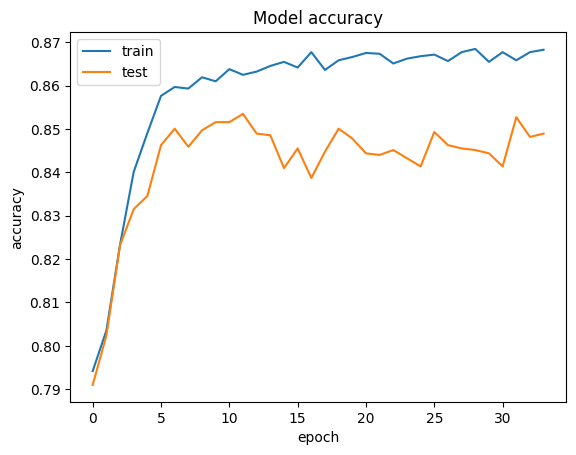

In [95]:
# summarize history for accuracy

plt.plot(model.history['accuracy'])
plt.plot(model.history['val_accuracy'])

plt.title('Model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')

plt.legend(['train', 'test'], loc='upper left')
plt.show()

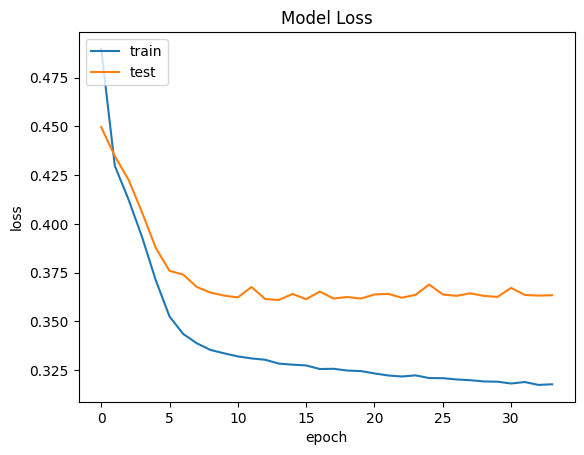

In [96]:
# summarize history for loss

plt.plot(model.history['loss'])
plt.plot(model.history['val_loss'])

plt.title('Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')

plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [97]:
# Making Prediction

y_pred = classifier.predict(x_test)
y_pred = (y_pred > 0.5)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [98]:
# Makeing Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
cm

array([[1536,   71],
       [ 205,  188]])

In [99]:
# Getting accuraccy score

from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.862

In [101]:
# Getting the weights assigned to each neuron

# classifier.get_weights()